# DatF Project - Part 1

`2026, Block 2`

Your assessment in DatF is based on 4 biweekly assignments. A part of those assignments will be an ongoing project aiming to teach you how to write good code in the context of something larger than your usual day-to-day lab notebooks. 
Specifically we will take a problem you are very familiar with: **using the error propagation formula to estimate uncertainties**, and show you how a powerful programming technique called 'Monte Carlo Simulation' can make your scientific work much easier and qualified. 

The error propagation formula states, that if a quantity $y$ is a function of $n$ variables such that $y = f(x_1, ..., x_n)$, then if we know the set of uncertainties $ \{\sigma_n\}$ we can calculate the uncertainty in $y$ as:

$$

\sigma_y = \sqrt{ \left( \frac{\partial f}{\partial x_1} \sigma_1 \right)^2 + \cdots + \left( \frac{\partial f}{\partial x_n} \sigma_n \right)^2}

$$


While the error propagation formula is a great tool, it has certain short commings:

1. **You have to differentiate:** This can be tedious if the quantity you are calculating is a complicated expression - but it is not even always possible! What if it's not differentiable? What if it's not even continuous?


2. **You are limited to $1^{st}$ order:** While the formula is exact for linear functions, it can produce very wrong predictions if your expression is sufficiently non-linear


3. **You are limited to small uncertainties:** If we anyhow apply the formula to non-linear relationships, we must demand that the uncertainties are small such that the function is roughly linear in comparison.


4. **You are limited to $\mu \pm \sigma$ summaries:** Quoting a mean and an error bar is fine and meaningful if we imagine a Gaussian error, but what if it is not Gaussian? A distribution is not defined just by its mean and spread.


5. **The formula cannot tell you when it falls short:** The formula will always confidently give you a std deviation to quote, but you must decide if that output is meaningful.


The purpose of Part 1 of this project, is to illustrate for you the power of 'Monte Carlo Simulation' and the potential hazards and inconveniences of applying the error propagation formula. 
Please read and solve the exercises as they are presented in order - good luck :)


In [1]:
# import packages
import matplotlib.pyplot as plt
import numpy as np

# Exercise 1 - Estimating the Range of a Canon Ball

[INSERT AN ILLUSTRATION]

Suppose we are launching a projectile from the ground at an angle $\theta \; [deg]$ and speed $v \; [m/s]$. Assuming no air resistance, the range of projectile once it hits the ground again $\R \; [m]$ is given by:

$$

R(v,\theta) = \frac{v^2}{g} \sin (2\theta)

$$

Where $g = 9.82 \; m/s^2$ is the gravitational acceleration. Say that we know the launch angle and speed with some uncertainties and we want to estimate the resulting uncertainty in the range. 

> **TASK 1:** derive an expression for the uncertainty $\sigma_R$ using the error propagation formula.


ANSWER:

$$
\sigma_R = \sqrt{\left(\frac{2v}{g}\sin(2\theta)\sigma_v \right)^2 + \left( \frac{2v^2}{g} \cos (2\theta) \sigma_\theta \right)^2}
$$

*The purpose here is to suffer differentiating something slightly complicated, and to establish something familiar*

> **TASK 2:** insert your expression in the cell below and print the estimated range for the defined parameters: $\theta = 30 \pm 1 ^\circ$ and $v = 10.0 \pm 0.1 \; m/s$

In [ ]:
# Estimate the range and its uncertainty using the error propagation formula

rad_per_deg = np.pi / 180         # convert degrees to radians

# declare parameters
theta = 35 * rad_per_deg          # rad
sigma_theta = 1 * rad_per_deg     # rad
v = 10.0                          # m/s 
sigma_v = 0.1                     # m/s 
g = 9.82                          # m/s^2

# calculate the range and its uncertainty
R = (v**2 / g) * np.sin(2 * theta)
sigma_R = ...                     # fill out using your derived expression

# -------------------------------------------------------------------------------------------------------------------
# ANSWER:
sigma_R = np.sqrt((2 * v / g * np.sin(2 * theta) * sigma_v)**2 + (v**2 / g * 2 * np.cos(2 * theta) * sigma_theta)**2)
# -------------------------------------------------------------------------------------------------------------------

# print the result
print(f"The estimated range is: {R:.2f} ± {sigma_R:.2f}") # the :.2f syntax formats the output to 2 decimal places


The estimated range is: 9.57 ± 0.23


If you succeded, you should see an estimated range of $9.57 \pm 0.23 \; m$ - great!



In [3]:
# Estimate the range and its uncertainty using monte carlo simulation

# get a random number generator - set a seed for reproducibility
rng = np.random.default_rng(42)

# define a number of samples to draw
n_samples = 10_000

# draw samples for theta and v from normal distributions
theta_samples = rng.normal(loc=theta, scale=sigma_theta, size=n_samples)
v_samples = rng.normal(loc=v, scale=sigma_v, size=n_samples)

# calculate the range for each sample
R_samples = (v_samples**2 / g) * np.sin(2 * theta_samples)

# estimate the mean and standard deviation of the range
R_mean = np.mean(R_samples)
R_std = np.std(R_samples)

# print the result
print(f"The estimated range is: {R_mean:.2f} ± {R_std:.2f}")

The estimated range is: 9.57 ± 0.23


## EXCITEMENT THAT WE DIDNT HAVE TO DIFFERENTIATE!

Launch from a certain height $h$ instead:

$$

R(v,\theta,h) = \frac{v \cos \theta}{g} \left( v \sin \theta + \sqrt{v^2 \sin^2 \theta + 2gh} \right)

$$

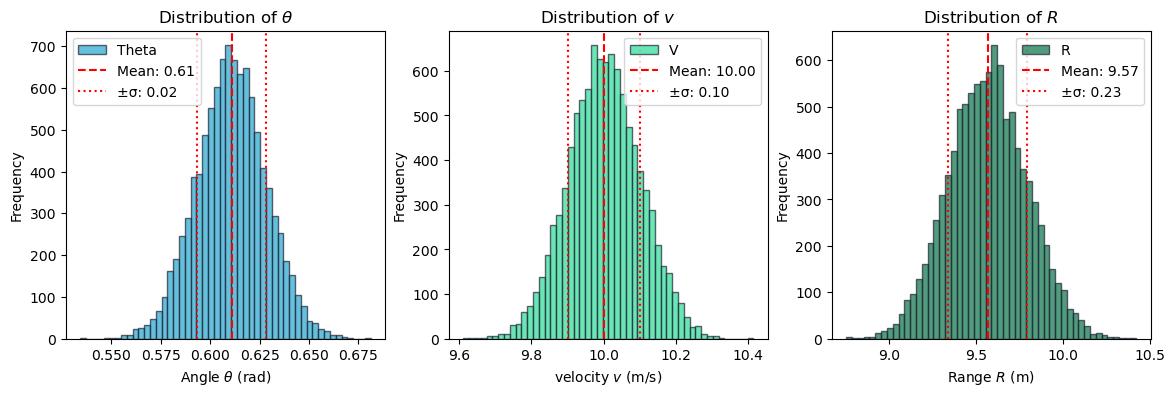

In [6]:
# Plot the distributions of theta, v, and R and mark the mean and standard deviation on the R distribution
plt.figure(figsize=(14, 4))

# Plot the distribution of theta
plt.subplot(1, 3, 1)
plt.hist(theta_samples, bins=50, alpha=0.7, label='Theta', color="#24a6ce", edgecolor="#212137")
plt.axvline(theta, color='red', linestyle='--', label=f'Mean: {theta:.2f}')
plt.axvline(theta + sigma_theta, color='red', linestyle=':', label=f'±σ: {sigma_theta:.2f}')
plt.axvline(theta - sigma_theta, color='red', linestyle=':')
plt.xlabel(r'Angle $\theta$ (rad)')
plt.ylabel('Frequency')
plt.title(r'Distribution of $\theta$')
plt.legend()

# Plot the distribution of v
plt.subplot(1, 3, 2)
plt.hist(v_samples, bins=50, alpha=0.7, label='V', color="#2bdb94", edgecolor="#212137")
plt.axvline(v, color='red', linestyle='--', label=f'Mean: {v:.2f}')
plt.axvline(v + sigma_v, color='red', linestyle=':', label=f'±σ: {sigma_v:.2f}')
plt.axvline(v - sigma_v, color='red', linestyle=':')
plt.xlabel(r'velocity $v$ (m/s)')
plt.ylabel('Frequency')
plt.title(r'Distribution of $v$')
plt.legend()

# Plot the distribution of R
plt.subplot(1, 3, 3)
plt.hist(R_samples, bins=50, alpha=0.7, label='R', color="#067245", edgecolor="#212137")
plt.axvline(R_mean, color='red', linestyle='--', label=f'Mean: {R_mean:.2f}')
plt.axvline(R_mean + R_std, color='red', linestyle=':', label=f'±σ: {R_std:.2f}')
plt.axvline(R_mean - R_std, color='red', linestyle=':')
plt.xlabel(r'Range $R$ (m)')
plt.ylabel('Frequency')
plt.title(r'Distribution of $R$')
plt.legend()

plt.show()

## Stuff to notice and explain 

- The formula predicts $R = R_{max}=10.18$ at $\theta=45^\circ$. Why does it predict zero uncertainty even though the angle is uncertain? (vanishing derivative)
- The MC predicts the correct std of around 0.85 m. Why is the mean less than the maximum? (All angles around 45 fall shorter. $E(f(x)) \neq f(E(x))$)
- Is the $\mu$ +- $\sigma$ a good summary of the actual distribution? (No it is not a gaussian and the upper bound is impossible!)

# What if the input is not Gaussian? 

Let a source emit photons according to a Poisson distribution of $\mu=1, \; \sigma=1$. Then calculate the number of pairs using $C(n) = n(n-1)/2$.

Compare the error formula $0 \pm 0.5$ with the poisson $0.5 \pm 1.22$ 

**Lesson:** propagate the complete distribution rather than an errorbar.

*NB: what causes the breakdown is not the non-gaussianity, its the nonlinearity of C and the substantial spread in the input.*



Error propagation formula approach: mean = 0.00, std = 0.50
Poisson simulation approach: mean = 0.50, std = 1.26
Empirical distribution result: mean = 0.50, std = 0.50


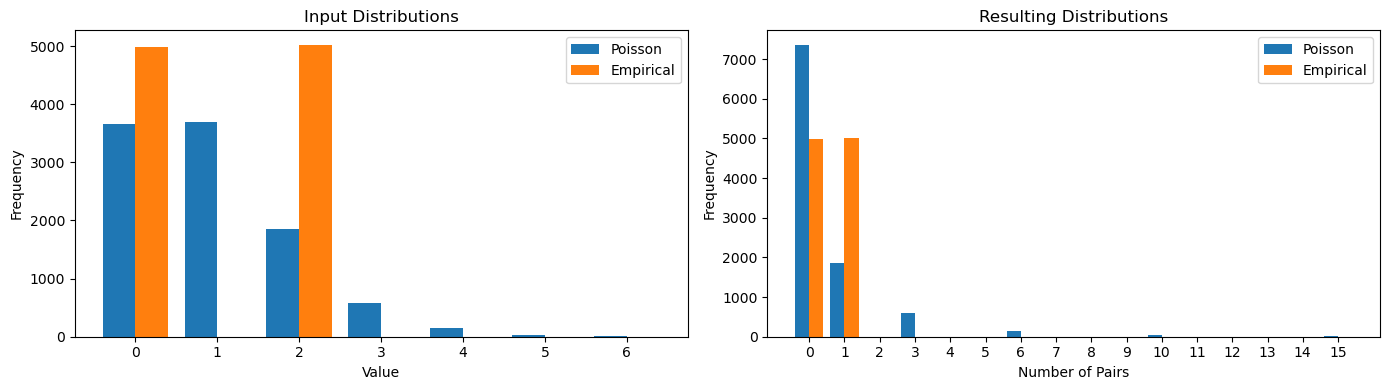

In [ ]:
mean_input = 1.0 
std_input = 1.0 

# function for calculating number of pairs
def c(n):
    return n * (n - 1) / 2

# Error propagation formula approach:
formula_mean = c(mean_input)
formula_std = (mean_input - 1/2) * std_input
print(f"Error propagation formula approach: mean = {formula_mean:.2f}, std = {formula_std:.2f}")
# __________________________________________________________________________________________________

# Poisson simulation approach:

# draw samples from a poisson distribution
rng = np.random.default_rng(42)
n_samples = 10_000
poisson_input = rng.poisson(lam=mean_input, size=n_samples)

# calculate the number of pairs for each sample
poisson_pairs = c(poisson_input)

# estimate the mean and standard deviation of the number of pairs
poisson_mean = np.mean(poisson_pairs)
poisson_std = np.std(poisson_pairs)
print(f"Poisson simulation approach: mean = {poisson_mean:.2f}, std = {poisson_std:.2f}")
# __________________________________________________________________________________________________

# Empirical distribution:

# draw samples from the empirical distribution with replacement
empirical_distribution = [0, 2]
empirical_input = rng.choice(empirical_distribution, size=n_samples, replace=True) 

# calculate the number of pairs for each sample
empirical_pairs = c(empirical_input)

# estimate the mean and standard deviation of the number of pairs
empirical_mean = np.mean(empirical_pairs)
empirical_std = np.std(empirical_pairs)
print(f"Empirical distribution result: mean = {empirical_mean:.2f}, std = {empirical_std:.2f}")
# __________________________________________________________________________________________________

# TASKS FOR STUDENTS:
#   plot histogram of poisson and empirical inputs
#   plot histogram of poisson and empirical pairs
#   comment on their differences even though both have the same mean +- std

# EXAMPLE SOLUTION:


# Plot raw frequency distributions using histogram-derived centers and heights
plt.figure(figsize=(14, 4))

bar_width = 0.4

# Input distributions
input_edges = np.arange(
    -0.5,
    max(np.max(poisson_input), np.max(empirical_input)) + 1.5,
    1
)

poisson_input_heights, _ = np.histogram(
    poisson_input, bins=input_edges, density=False
)
empirical_input_heights, _ = np.histogram(
    empirical_input, bins=input_edges, density=False
)
input_centers = (input_edges[:-1] + input_edges[1:]) / 2

plt.subplot(1, 2, 1)
plt.bar(
    input_centers - bar_width / 2,
    poisson_input_heights,
    width=bar_width,
    label="Poisson"
)
plt.bar(
    input_centers + bar_width / 2,
    empirical_input_heights,
    width=bar_width,
    label="Empirical"
)
plt.xlabel("Value")
plt.ylabel("Frequency")
plt.title("Input Distributions")
plt.xticks(input_centers)
plt.legend()

# Resulting pair distributions
pair_edges = np.arange(
    -0.5,
    max(np.max(poisson_pairs), np.max(empirical_pairs)) + 1.5,
    1
)

poisson_pair_heights, _ = np.histogram(
    poisson_pairs, bins=pair_edges, density=False
)
empirical_pair_heights, _ = np.histogram(
    empirical_pairs, bins=pair_edges, density=False
)
pair_centers = (pair_edges[:-1] + pair_edges[1:]) / 2

plt.subplot(1, 2, 2)
plt.bar(
    pair_centers - bar_width / 2,
    poisson_pair_heights,
    width=bar_width,
    label="Poisson"
)
plt.bar(
    pair_centers + bar_width / 2,
    empirical_pair_heights,
    width=bar_width,
    label="Empirical"
)
plt.xlabel("Number of Pairs")
plt.ylabel("Frequency")
plt.title("Resulting Distributions")
plt.xticks(pair_centers)
plt.legend()

plt.tight_layout()
plt.show()


# What if the input is not a standard distribution?

Adopt an empirical input with 50% no photons and 50% 2 photons. This has the same mean and std., but is another distribution.

Sample with replacement --> $0.5 \pm 0.5$

**Lesson:** The mean and std of an input is generally not enough to model the output uncertainties. Here we had three inputs of equal mean and std, but three different predictions

*NB:* motivate the introduction of an "Empirical" abstraction in the later API. (Constant, Distribution, Empirical, all belonging to Source)


# Summarize benefits and outline the ambition for the project

- never differentiate again
- propagate distributions rather than statistical summaries - almost trivial numerically
    - What can go wrong?
        - substantial spread
        - non-linearity
        - distribution awareness
- Three types: constants like $g$, standard distributions like Gaussian or Poisson, and empirical/non-standard finite distributions

Ambition:
- Make reusable code: we will create a package that you can reuse every time instead of rewriting the same code over and over in the lab
- Make shareable code: you will learn to make your code readible to others (and your later selves) and publish and download each others' packages
- Make extentable code: structure your code in a way so others (and your later selves) can build on top of it, rather than restructuring from project to project.